# 📊 Feature Engineering: Power Transformations (Box-Cox vs. Yeo-Johnson)

## 1. Overview & Context
This notebook explores **parametric power transformations** using Scikit-Learn's `PowerTransformer` engine. In data science, many machine learning algorithms (such as Linear Regression, Logistic Regression, and LDA) assume that numerical input features follow a stable, normal (Gaussian-like) distribution and possess constant variance (**homoscedasticity**). 

This notebook demonstrates how to stabilize variance, minimize skewness, and map skewed, non-normal distributions closer to a normal profile across a structured machine learning pipeline.

---

## 2. Core Methodologies

We implement and contrast the two primary variance-stabilizing transformation methods:

### 🔹 Box-Cox Transformation
*   **Mathematical Constraint:** Strictly requires **strictly positive data** ($x > 0$).
*   **How it works:** Finds an optimal power parameter $\lambda$ (lambda) to stabilize variance and minimize skewness. If your dataset contains zeros or negative values, this algorithm will fail.

### 🔹 Yeo-Johnson Transformation
*   **Mathematical Constraint:** Supports **all real numbers** ($x \le 0$, zero, and positive data).
*   **How it works:** Extends the capabilities of the Box-Cox method by modifying the power function to safely accommodate zero and negative values while achieving the same Gaussian properties.

---

1.  **Baseline Profiling:** Visualize un-transformed feature skewness using modern `sns.histplot(kde=True)` frameworks.
2.  **Transformer Fitting:** Isolate transformations by instantiating and fitting distinct variance engines via `pt.fit_transform(X_train)`.
3.  **Parameter Extraction:** Collect the optimized internal $\lambda$ attributes (`pt.lambdas_`) into a side-by-side Pandas summary comparison table.
4.  **Downstream Validation:** Feed the processed variables into a `LinearRegression` model to analyze improvements in predictive performance via $R^2$ scaling.



In [38]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LinearRegression

from sklearn.metrics import r2_score

from sklearn.preprocessing import PowerTransformer

In [40]:
df = pd.read_csv('concrete_data.csv')

In [41]:
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [42]:
df.shape

(1030, 9)

In [43]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [44]:
X = df.drop(columns=['Strength'])
y = df.iloc[:,-1]

In [45]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [46]:
# Applying Regression without any transformation
lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

r2_score(y_test, y_pred)

0.6275531792314848

In [47]:
# Cross checking with cross val score
lr = LinearRegression()
np.mean(cross_val_score(lr,X,y,scoring='r2'))

np.float64(0.4609940491662864)

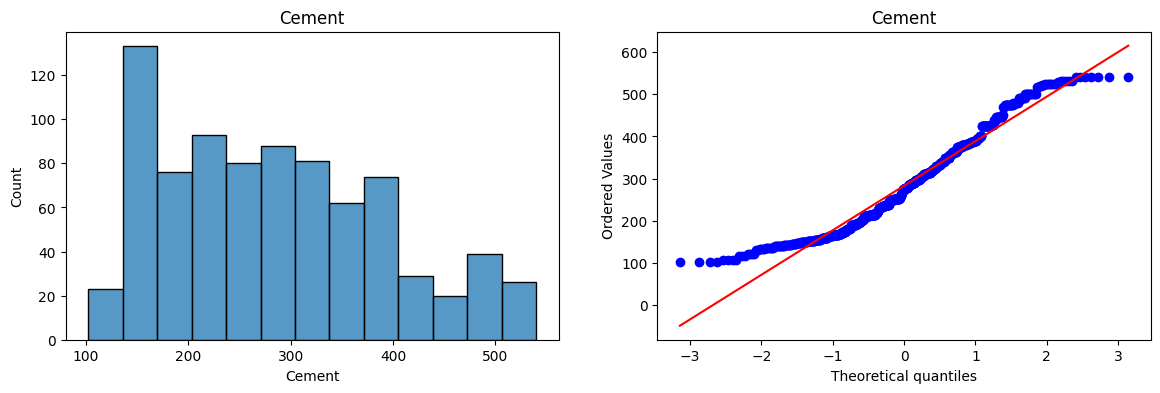

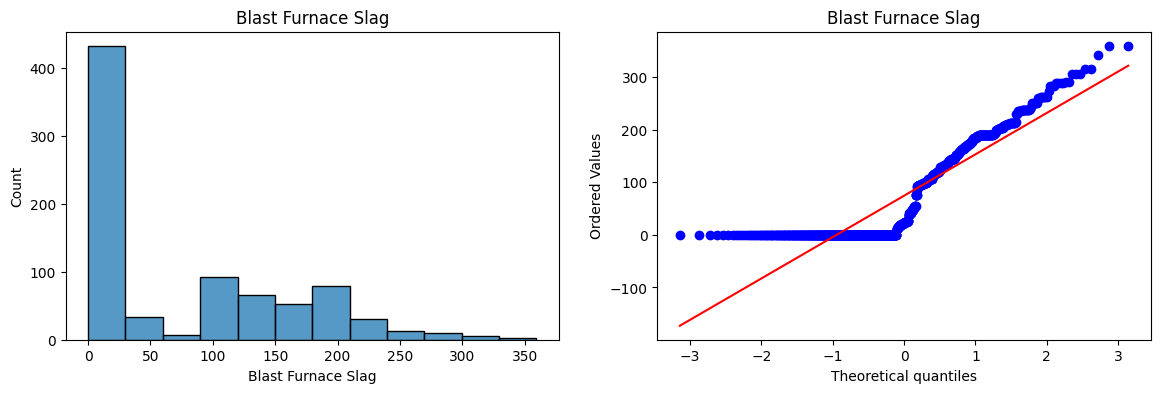

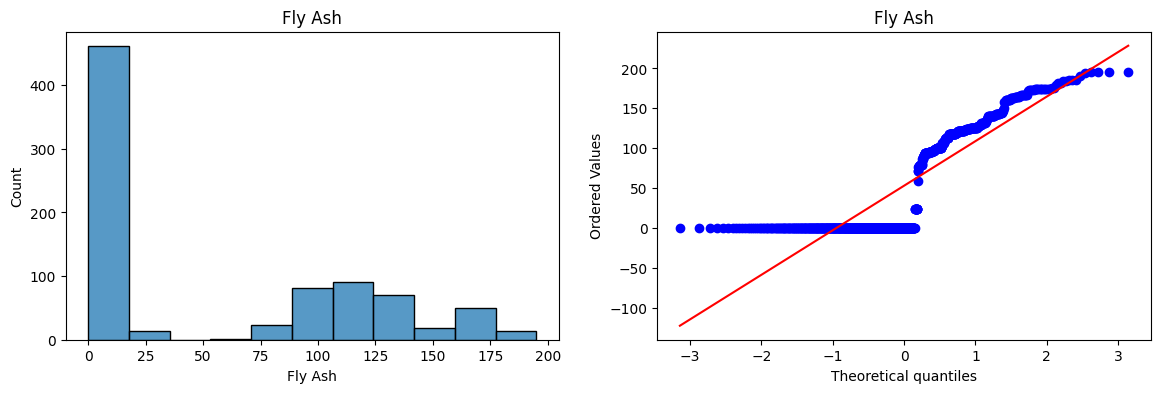

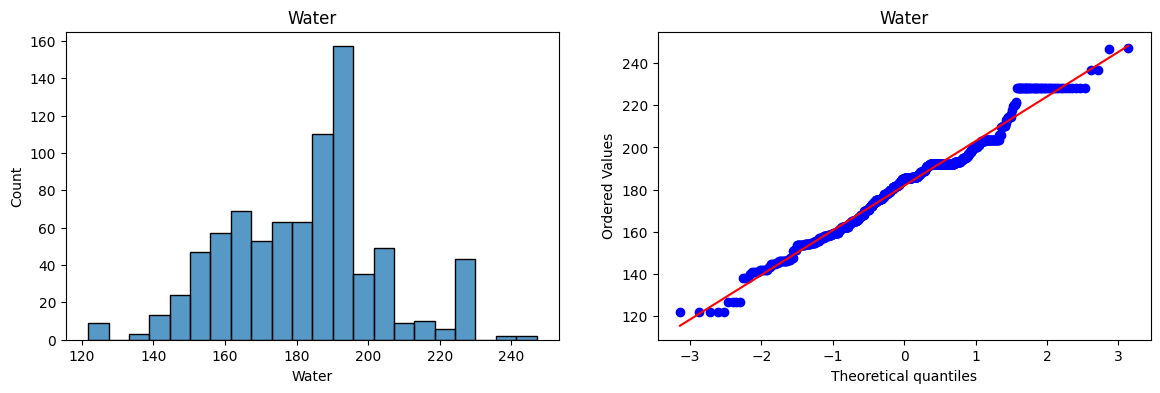

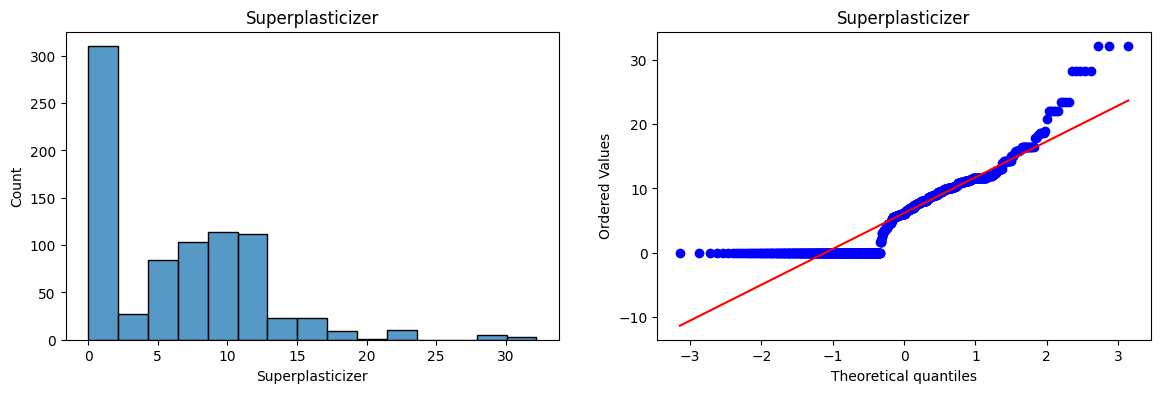

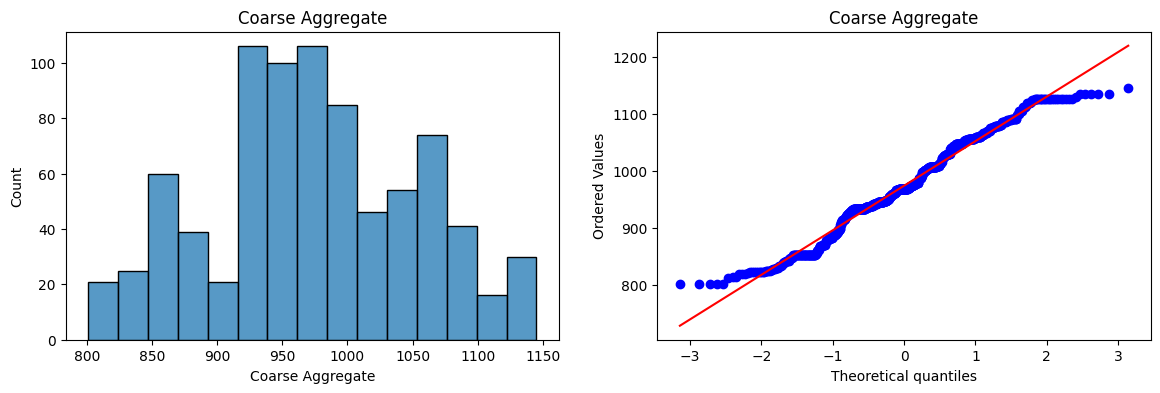

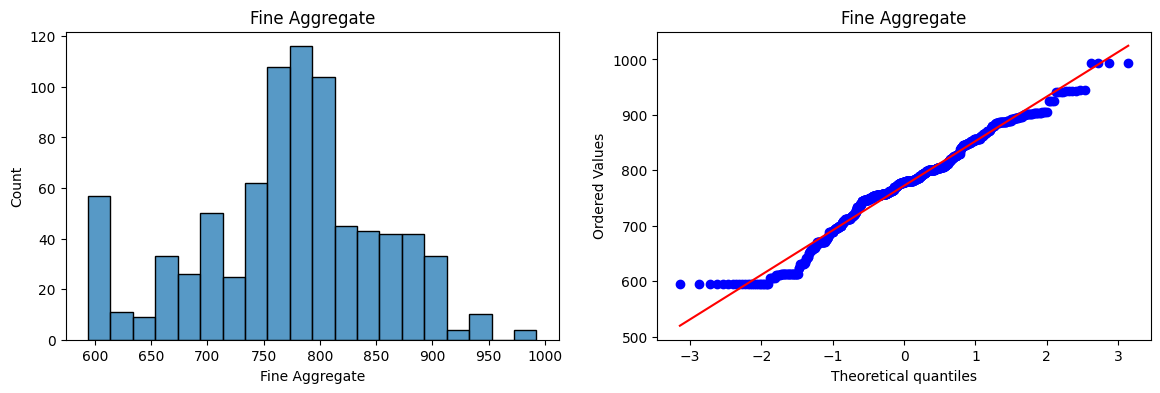

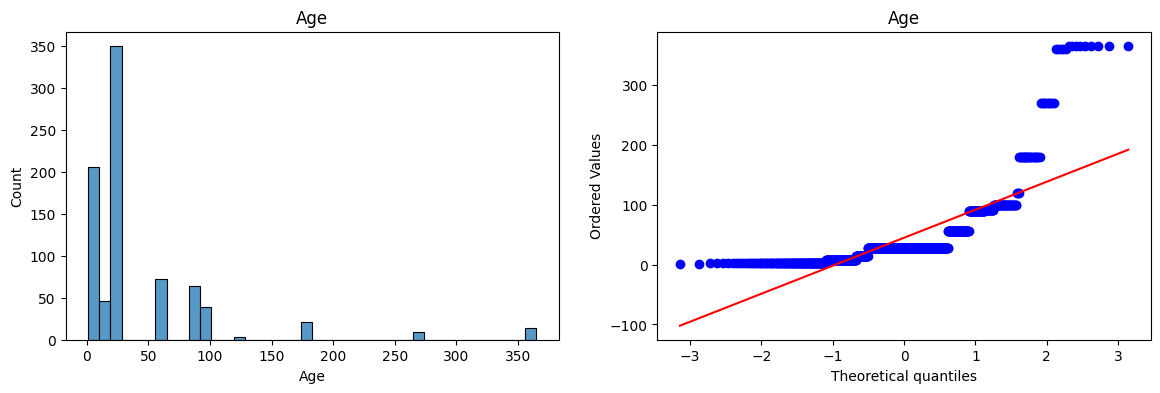

In [48]:
# Plotting the histplot without any transformation
for col in X_train.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train[col])
    plt.title(col)

    plt.subplot(122)
    stats.probplot(X_train[col], dist="norm", plot=plt)
    plt.title(col)

    plt.show()

In [58]:
# Apply Box-Cox Transformation

pt_bc = PowerTransformer(method='box-cox')

X_train_transformed = pt_bc.fit_transform(X_train+0.000001)
X_test_transformed = pt_bc.transform(X_test+0.000001)

pd.DataFrame({'cols':X_train.columns, 'box_cox_lambdas':pt_bc.lambdas_})

,cols,box_cox_lambdas
0,Cement,0.177025
1,Blast Furnace Slag,0.025093
2,Fly Ash,-0.038970
3,Water,0.772682
4,Superplasticizer,0.098811
5,Coarse Aggregate,1.129813
6,Fine Aggregate,1.782018
7,Age,0.066631


In [59]:
# Apply Linear Regression on Transfomed data

lr = LinearRegression()

lr.fit(X_train_transformed, y_train)
y_pred2 = lr.predict(X_test_transformed)

r2_score(y_test, y_pred2)

0.8047825008078886

In [60]:
# Using Cross Val Score

pt_bc = PowerTransformer(method='box-cox')
X_transformed = pt_bc.fit_transform(X+0.000001)

lr = LinearRegression()
np.mean(cross_val_score(lr, X_transformed, y, scoring='r2'))

np.float64(0.6662950326831086)

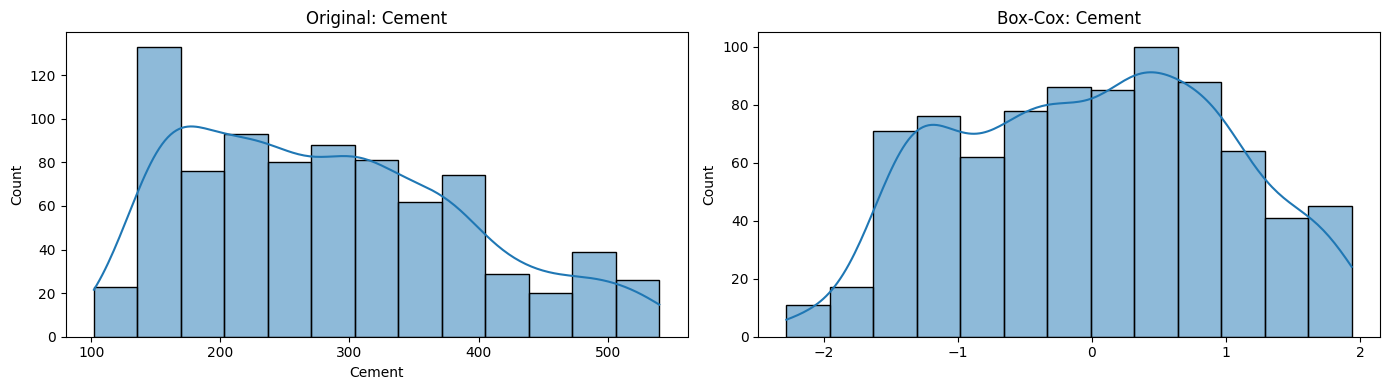

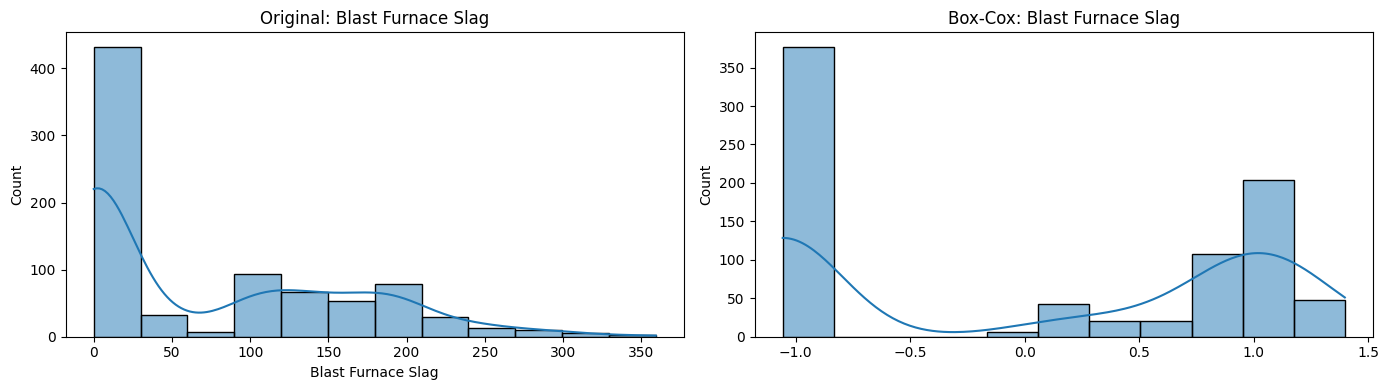

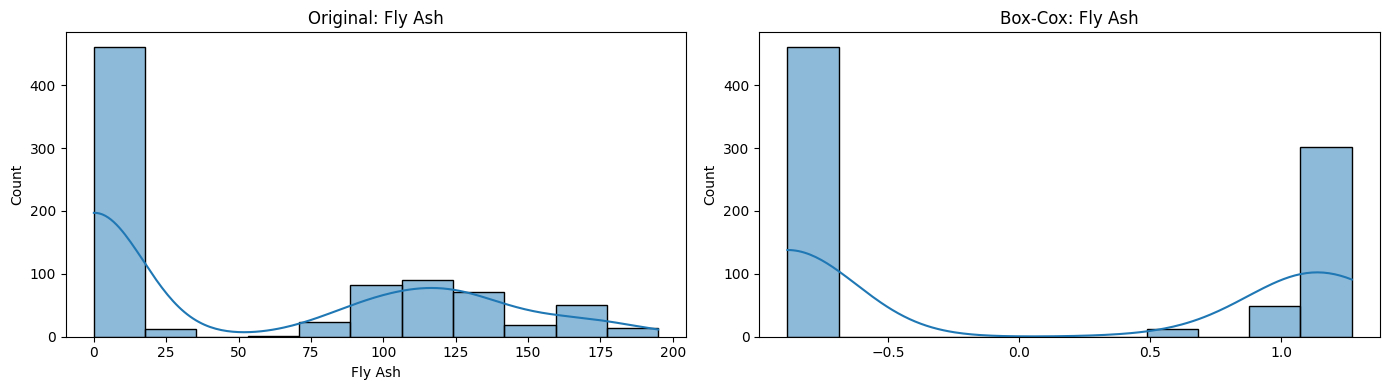

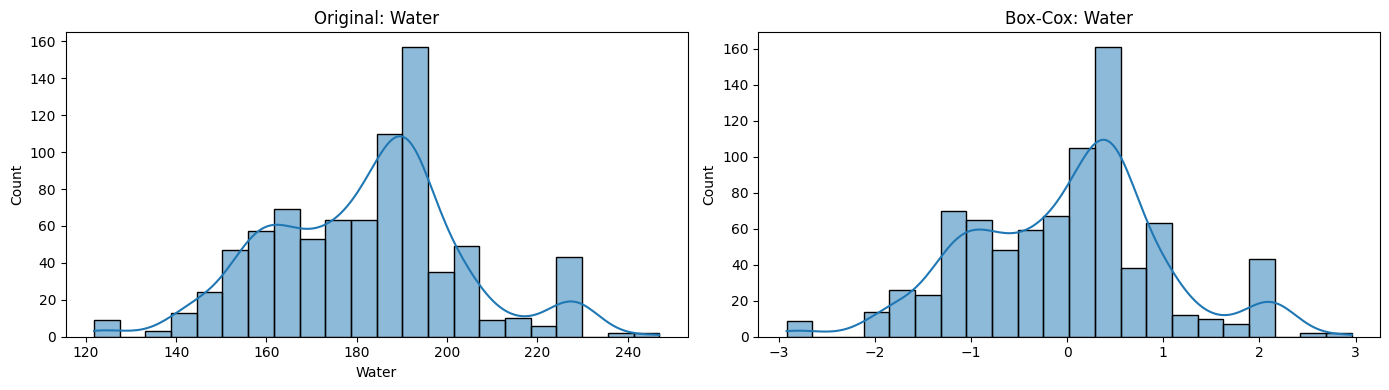

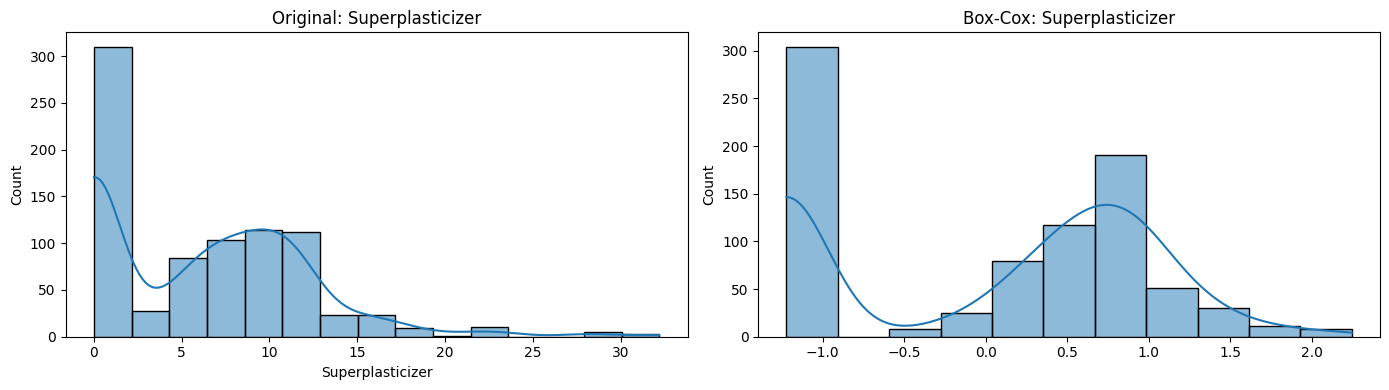

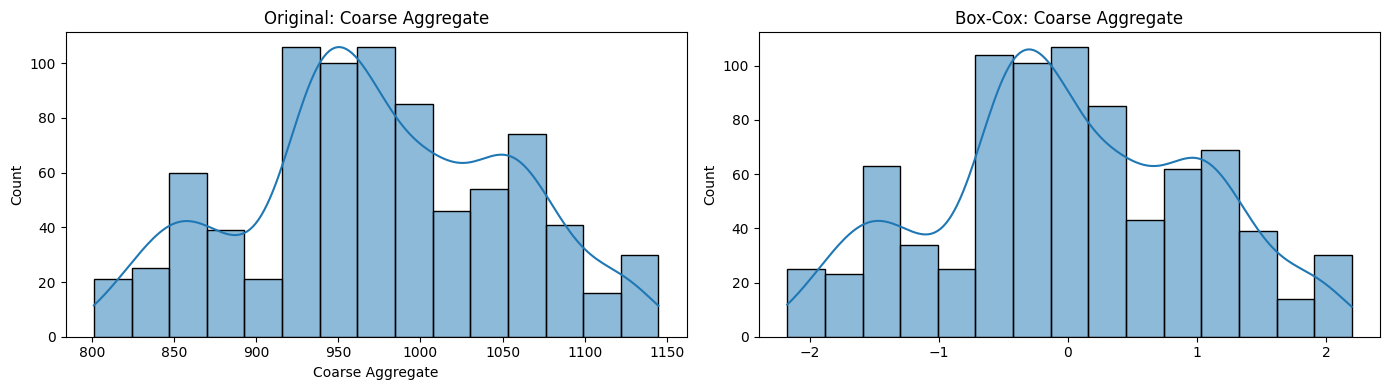

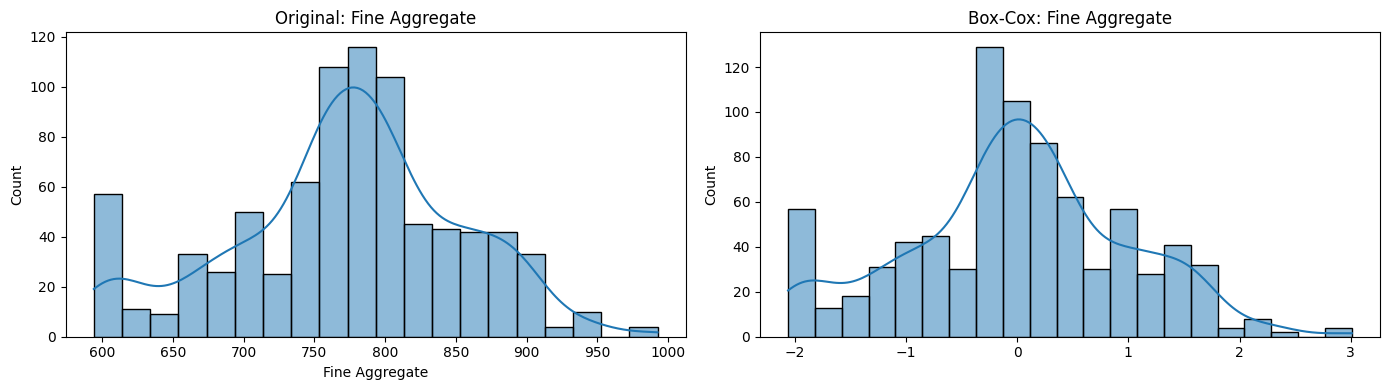

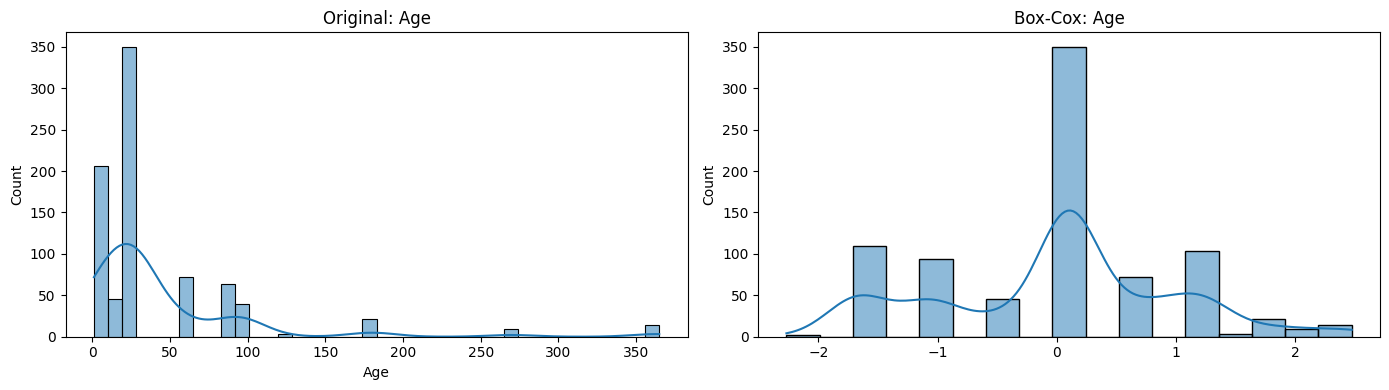

In [52]:
# Before and after comparison for Box-Cox Plot

# Loop through columns using the original DataFrame's column names and their positions
for i, col in enumerate(X_train.columns):
    plt.figure(figsize=(14, 4))
    
    # 1. Plot original data
    plt.subplot(121)
    sns.histplot(X_train[col], kde=True)  # Updated to modern histplot
    plt.title(f"Original: {col}")
    
    # 2. Plot transformed data (slice the NumPy array by column index i)
    plt.subplot(122)
    sns.histplot(X_train_transformed[:, i], kde=True) 
    plt.title(f"Box-Cox: {col}")
    
    plt.tight_layout()
    plt.show()


In [61]:
# Apply Yeo-Johnson Transform

pt_yj = PowerTransformer()

X_train_transformed2 = pt_yj.fit_transform(X_train)
X_test_transformed2 = pt_yj.transform(X_test)

lr = LinearRegression()
lr.fit(X_train_transformed2, y_train)

y_pred3 = lr.predict(X_test_transformed2)

print(r2_score(y_test, y_pred3))

pd.DataFrame({'cols':X_train.columns, 'Yeo_Johnson_lambdas':pt_yj.lambdas_})

0.8161906511066098


,cols,Yeo_Johnson_lambdas
0,Cement,0.174348
1,Blast Furnace Slag,0.015715
2,Fly Ash,-0.161447
3,Water,0.771307
4,Superplasticizer,0.253935
5,Coarse Aggregate,1.130050
6,Fine Aggregate,1.783100
7,Age,0.019885


In [63]:
# Apply Cross Val Score

pt_yj = PowerTransformer()
X_transformed2 = pt_yj.fit_transform(X)

lr = LinearRegression()
np.mean(cross_val_score(lr, X_transformed2, y, scoring='r2'))

np.float64(0.6834625126992443)

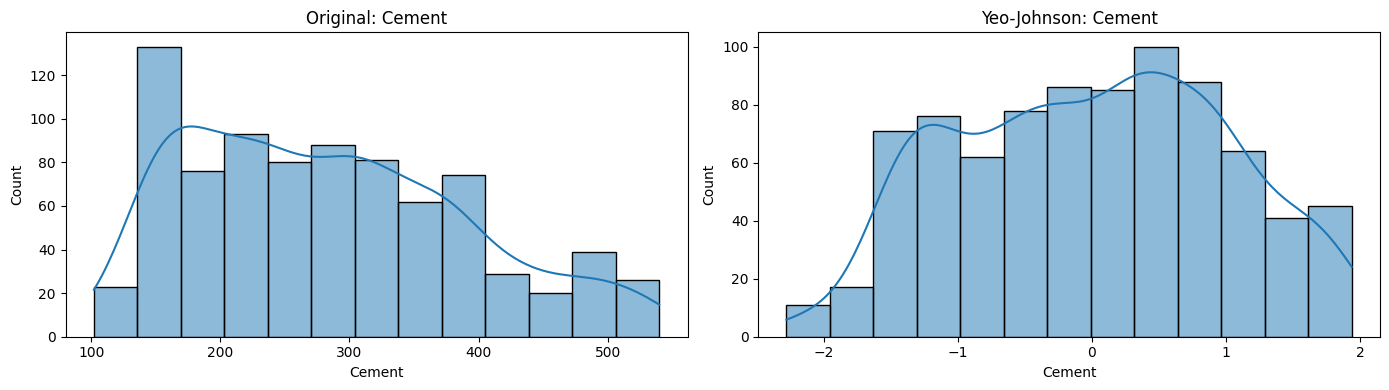

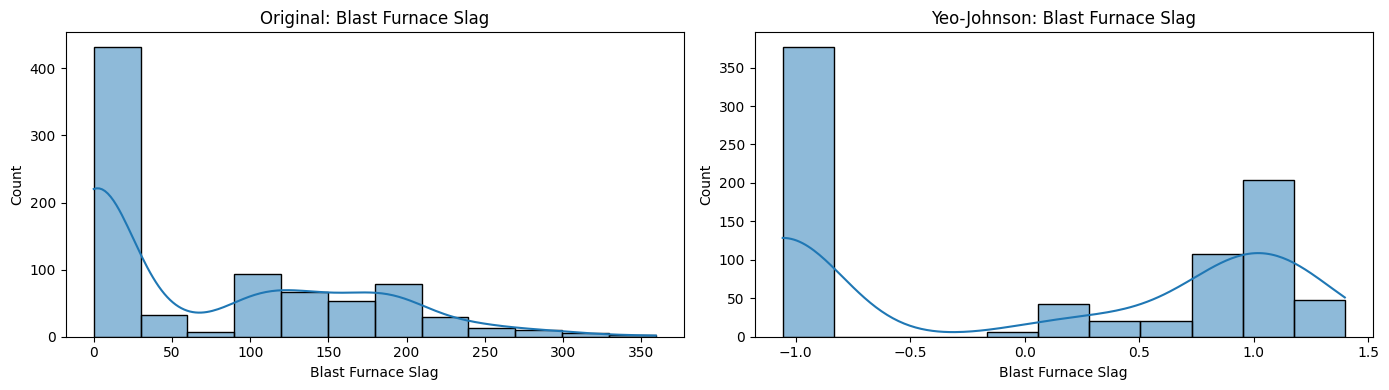

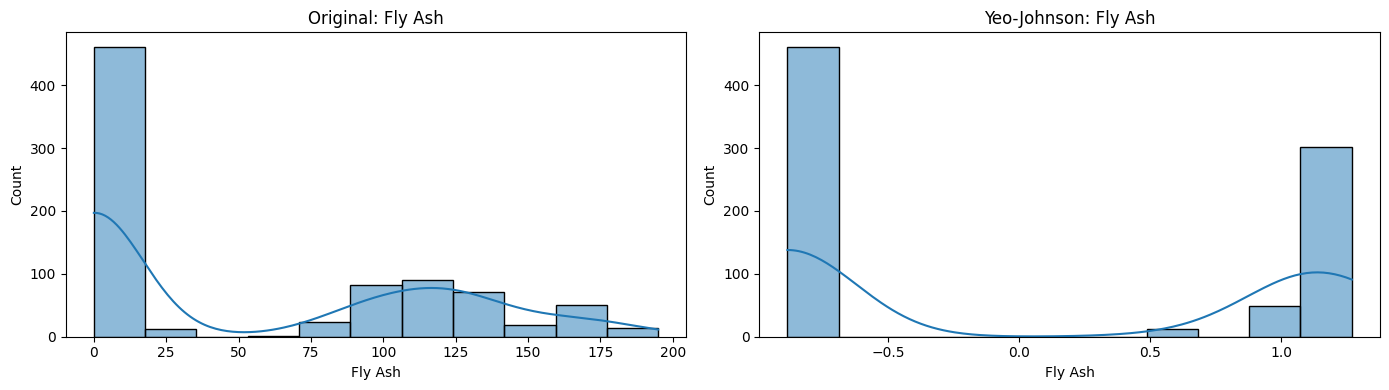

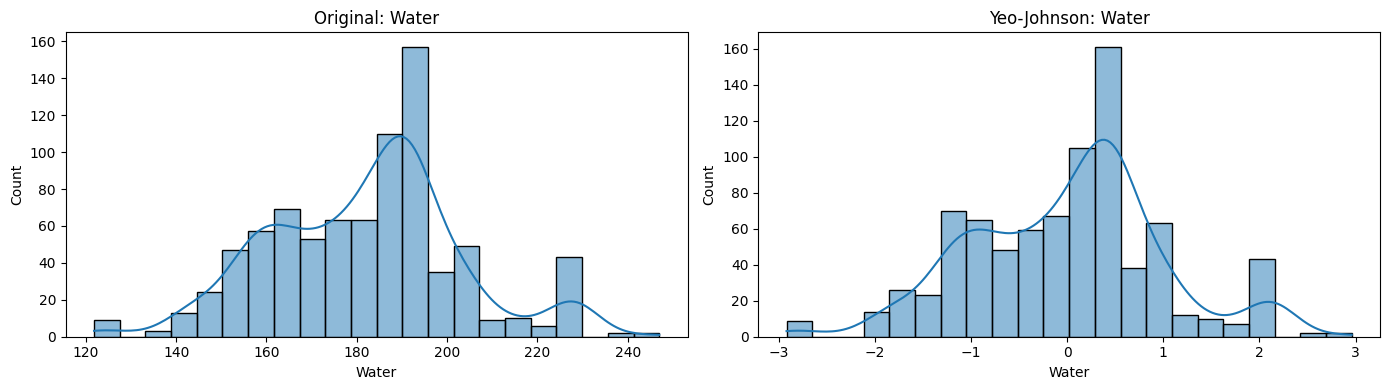

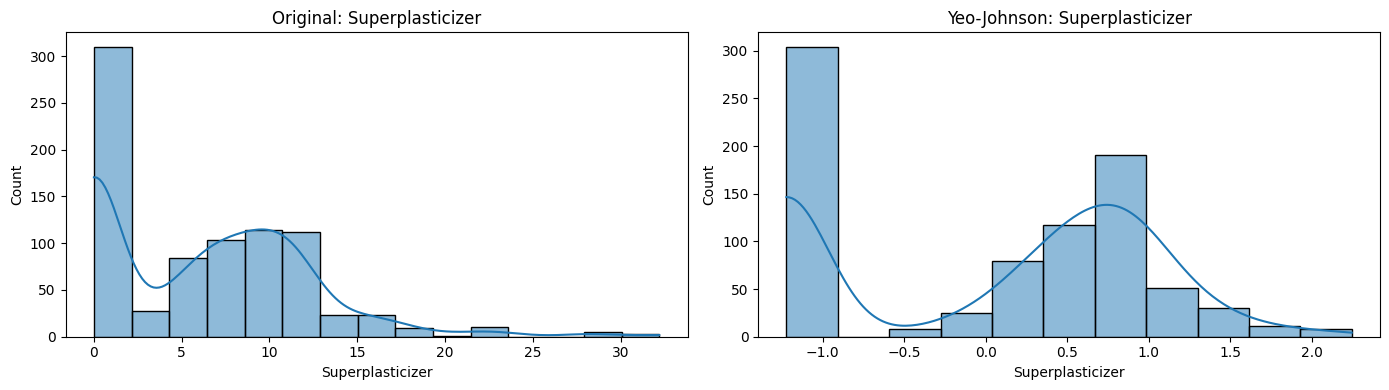

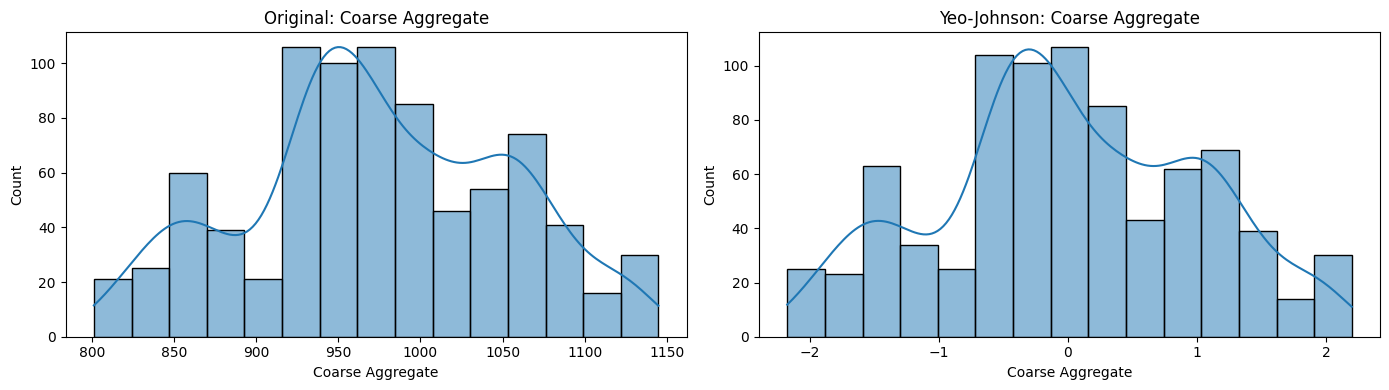

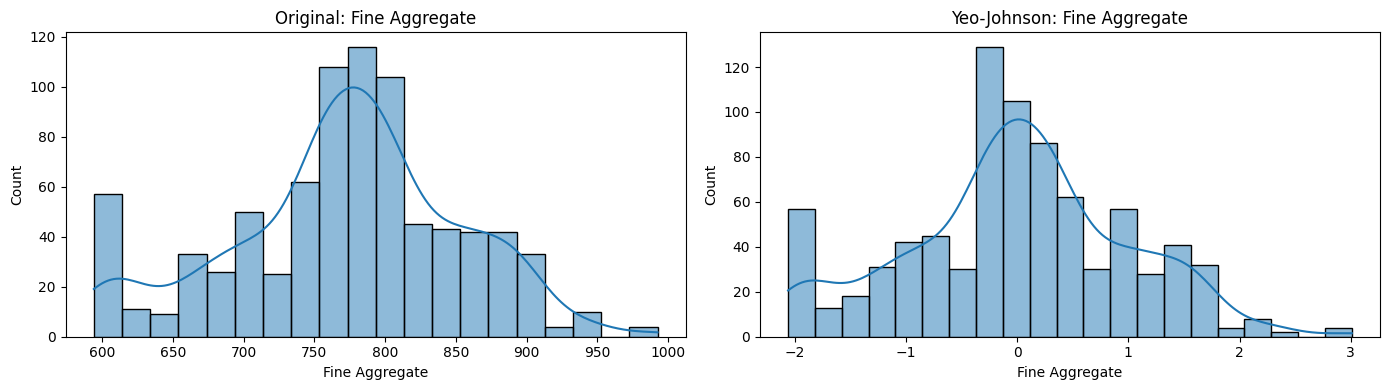

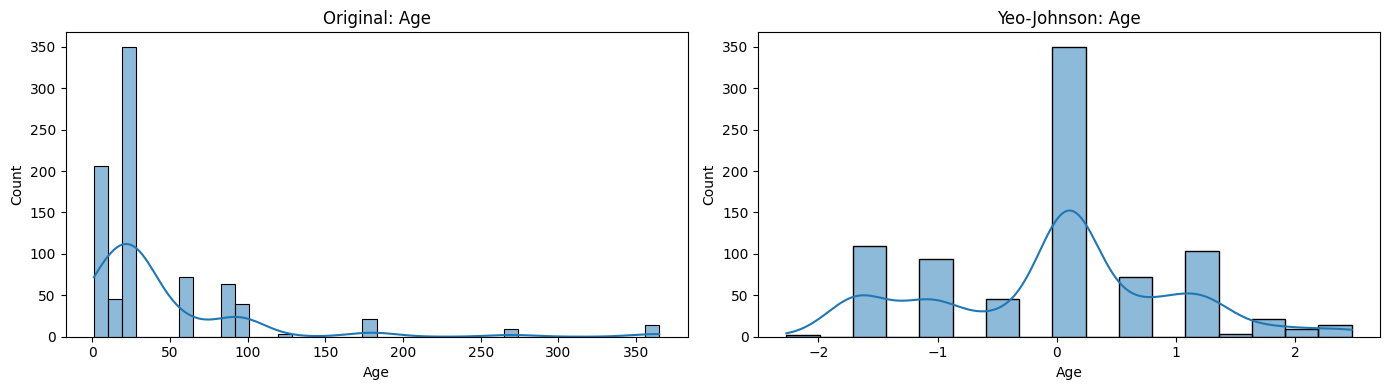

In [64]:
# Convert transformed numpy array back into a DataFrame
X_train_transformed2 = pd.DataFrame(X_train_transformed2, columns=X_train.columns)

# Before and after comparison for Yeo-Johnson
for col in X_train_transformed2.columns:
    plt.figure(figsize=(14, 4))
    
    # Left subplot: Original distribution
    plt.subplot(121)
    sns.histplot(X_train[col], kde=True)
    plt.title(f"Original: {col}")
    
    # Right subplot: Transformed distribution
    plt.subplot(122)
    sns.histplot(X_train_transformed2[col], kde=True)
    plt.title(f"Yeo-Johnson: {col}")
    
    plt.tight_layout()
    plt.show()


In [65]:
# Corrected syntax using a standard Python dictionary inside pd.DataFrame()
lambda_df = pd.DataFrame({
    'cols': X_train.columns, 
    'box_cox_lambdas': pt_bc.lambdas_,      # Assumes pt is your Box-Cox transformer
    'Yeo_Johnson_lambdas': pt_yj.lambdas_  # Assumes pt1 is your Yeo-Johnson transformer
})

lambda_df


,cols,box_cox_lambdas,Yeo_Johnson_lambdas
0,Cement,0.172271,0.169544
1,Blast Furnace Slag,0.025273,0.016633
2,Fly Ash,-0.032412,-0.136480
3,Water,0.809568,0.808438
4,Superplasticizer,0.099711,0.264160
5,Coarse Aggregate,1.129168,1.129395
6,Fine Aggregate,1.829625,1.830764
7,Age,0.048975,0.001771
